# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль 3:** Ансамблевые методы (базовый и продвинутый уровень)  
**Датасет:** Telco Customer Churn  

**Выполнила:** Жданова Анна Александровна  
**Группа:** ПКТб-23-1   
**Преподаватель:** Спирин И.С.  

**Ссылка на репозиторий:** https://github.com/ZhdanovaAnna/ml-course-zhdanova

**Путь к модулю:** `module-3-churn/notebook.ipynb`  

**Дата:** 20.10.2026 

## 2. Введение

### Постановка задачи

В работе решается задача **бинарной классификации**: по сведениям о клиенте телекоммуникационной компании необходимо предсказать, уйдёт ли клиент (`Churn = Yes`) или останется (`Churn = No`). Целевая переменная принимает два значения: `1` - клиент ушёл, `0` - клиент остался.

**Ансамблевые методы** объединяют несколько моделей, чтобы получить более устойчивый и точный прогноз, чем при использовании одного алгоритма. В этой работе сравниваются Random Forest, XGBoost, LightGBM и CatBoost. Дополнительно лучшая по результатам базового сравнения модель оптимизируется с помощью Optuna, а её предсказания объясняются через SHAP.

### Почему ансамбли?

Разные деревья могут находить разные закономерности в данных. Random Forest снижает разброс за счёт обучения множества деревьев на случайных подвыборках и признаках, а градиентный бустинг последовательно исправляет ошибки предыдущих деревьев. Сравнение нескольких алгоритмов позволяет выбрать модель с хорошим балансом качества, скорости и интерпретируемости.

### Какая метрика важнее?

Одной Accuracy недостаточно: из-за дисбаланса классов модель может часто предсказывать наиболее распространённый класс `No` и при этом пропускать клиентов, которые собираются уйти. Поэтому основными метриками будут **ROC-AUC** (качество ранжирования клиентов по риску оттока) и **Recall** класса `Yes` (доля действительно ушедших клиентов, которых модель обнаружила). F1 помогает оценить баланс Precision и Recall. Выбор порога вероятности можно менять в зависимости от стоимости удерживающей кампании и допустимого числа ложных тревог.

### Цель работы

1. Обучить четыре ансамблевые модели и сравнить качество и время обучения.

2. Оптимизировать LightGBM с помощью Optuna по ROC-AUC на стратифицированной кросс-валидации.

3. Интерпретировать важные признаки и отдельные прогнозы с помощью Feature Importance и SHAP.

## 3. Теоретическая часть

### 3.1. Ансамбль

**Ансамбль** - это метод машинного обучения, при котором прогноз строится на основе нескольких базовых моделей. Идея заключается в том, что ошибки отдельных моделей могут компенсировать друг друга. Ансамбли особенно полезны для табличных данных, где нелинейные зависимости и взаимодействия признаков затрудняют построение простой модели. Качество ансамбля зависит от точности базовых моделей и разнообразия их ошибок.

### 3.2. Bagging и Boosting

**Bagging** обучает несколько моделей независимо на случайных выборках обучающих данных, после чего объединяет их ответы. Для классификации обычно используется голосование или усреднение вероятностей; подход помогает снизить разброс модели. **Boosting** строит модели последовательно: каждая следующая модель ориентируется на ошибки текущего ансамбля. Бустинг способен добиться высокого качества, но требует настройки скорости обучения, глубины деревьев и регуляризации.

Формула усреднения для bagging:

$$
H(x) = \frac{1}{M}\sum_{i=1}^{M} h_i(x)
$$

Формула взвешенного ансамбля для boosting:

$$
H(x) = \sum_{i=1}^{M} \alpha_i h_i(x)
$$

где $h_i(x)$ - прогноз отдельной модели, $M$ - количество моделей, а $alpha_i$ - вес модели в ансамбле.

### 3.3. Random Forest

**Random Forest** - ансамбль деревьев решений, обучаемых на bootstrap-выборках. При каждом разбиении рассматривается случайное подмножество признаков, что уменьшает сходство деревьев. Для классификации результаты объединяются голосованием или усреднением вероятностей. Метод устойчив и является хорошей базовой моделью, однако на очень больших данных может обучаться медленнее специализированных реализаций градиентного бустинга.

### 3.4. Градиентный бустинг: XGBoost, LightGBM и CatBoost

Градиентный бустинг добавляет деревья поэтапно, уменьшая функцию потерь. **XGBoost** использует регуляризацию и эффективные алгоритмические оптимизации. **LightGBM** ориентирован на быстрое обучение деревьев и экономное использование памяти; важные параметры включают `num_leaves`, `max_depth` и `learning_rate`. **CatBoost** применяет специальные механизмы для снижения смещения при бустинге и особенно удобен при наличии категориальных признаков. В этой работе категориальные столбцы кодируются до обучения, чтобы все четыре модели получали одинаковую матрицу признаков.

### 3.5. Optuna

**Optuna** - библиотека автоматического подбора гиперпараметров. В заданной objective-функции задаются диапазоны параметров и метрика, которую необходимо максимизировать или минимизировать. TPE-сэмплер использует результаты предыдущих испытаний для выбора перспективных конфигураций, поэтому поиск может быть эффективнее полного перебора. Качество параметров оценивается на кросс-валидации, а тестовая выборка остаётся отдельной для итоговой проверки.

### 3.6. SHAP

**SHAP** основан на значениях Шепли из теории кооперативных игр и распределяет вклад признаков в предсказание модели. Summary plot показывает общую важность признаков и направление их влияния, bar plot сравнивает средние абсолютные SHAP-значения, waterfall plot объясняет прогноз одного клиента, а dependence plot показывает, как значение отдельного признака связано с его вкладом в прогноз. SHAP объясняет поведение уже обученной модели, но сам по себе не доказывает причинно-следственную связь.

### 3.7. Сравнение моделей

| Модель | Подход | Сильные стороны | Особенности |
|---|---|---|---|
| Random Forest | Bagging | Устойчивость, простая настройка | Много деревьев увеличивают размер модели |
| XGBoost | Boosting | Гибкая регуляризация, высокое качество | Требует настройки параметров |
| LightGBM | Boosting | Быстрое обучение, эффективная работа с таблицами | Нужно контролировать сложность деревьев |
| CatBoost | Boosting | Хорошая поддержка категориальных данных | Обучение может быть медленнее на небольших наборах |

Схема работы: данные → очистка и кодирование → стратифицированное разделение → обучение четырёх моделей → сравнение метрик → Optuna → SHAP → сохранение артефактов.

## 4. Описание данных

### 4.1. Источник

Используется датасет **Telco Customer Churn**. Исходный источник датасета: [Kaggle — Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). В работе используется файл `Telco-Customer-Churn.csv`.

### 4.2. Структура данных

Датасет содержит сведения о 7043 клиентах и 21 столбец: идентификатор клиента, 19 признаков и целевую переменную `Churn`. 
Цель - определить, прекратил ли клиент пользоваться услугами компании. `customerID` является идентификатором, поэтому в качестве предиктора не используется.

### 4.3. Основные поля

| Столбец | Тип до обработки | Значение |
|---|---|---|
| `customerID` | object | Уникальный идентификатор клиента |
| `gender` | object | Пол клиента |
| `SeniorCitizen` | int | Признак пожилого клиента (0/1) |
| `tenure` | int | Стаж клиента в месяцах |
| `MonthlyCharges` | float | Ежемесячная плата |
| `TotalCharges` | object | Суммарные начисления; требует преобразования в число |
| `Contract` | object | Тип контракта |
| `InternetService` | object | Тип интернет-услуги |
| `Churn` | object | Целевая переменная: Yes/No |

Ниже код выводит фактический размер файла, первые строки, типы столбцов, статистики и доли классов. Это позволяет сверить описание с реально загруженными данными.

In [2]:
# Импортируем библиотеки
import os
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Настраиваем отображение графиков и подавляем только предупреждения
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

df_raw = pd.read_csv('data/telco_churn.csv')

# Выводим обязательные сведения о размере и первых наблюдениях
print("Размер датасета:", df_raw.shape)
display(df_raw.head())
print("\nТипы данных и непустые значения:")
df_raw.info()
print("\nОписательная статистика:")
display(df_raw.describe(include="all").T)

# Показываем распределение целевой переменной в количестве и процентах
display(df_raw["Churn"].value_counts().rename("Количество").to_frame())
display((df_raw["Churn"].value_counts(normalize=True) * 100).round(2).rename("Доля, %").to_frame())

Размер датасета: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Типы данных и непустые значения:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Количество
Churn,
No,5174
Yes,1869


,"Доля, %"
Churn,
No,73.46
Yes,26.54


### Вывод по разделу 4

Проверка подтверждает, что в файле находятся 7043 записи и 21 столбец. 

Целевая переменная имеет два класса, причём оставшихся клиентов больше, чем ушедших. Следовательно, при оценке качества нужно смотреть не только на Accuracy, но и на Recall, F1 и ROC-AUC. 

Столбец `TotalCharges` имеет строковый тип, поэтому перед анализом и обучением его необходимо преобразовать в числовой.

## 5. Подготовка данных и EDA

В этом разделе проверяются пропуски и распределения признаков, строятся визуализации, выполняется преобразование `TotalCharges`, создаются дополнительные признаки и кодируются категориальные значения. 

Пропуски в `TotalCharges` возникают из-за пустых строк в исходном CSV; после преобразования они заменяются медианой. 

Медиана менее чувствительна к экстремальным значениям, чем среднее. `customerID` исключается из модели, поскольку это технический идентификатор, а не содержательная характеристика клиента.

Пропуски до обработки:


,Количество
TotalCharges,11


Медиана TotalCharges для заполнения: 1397.48
Пропусков после обработки: 0


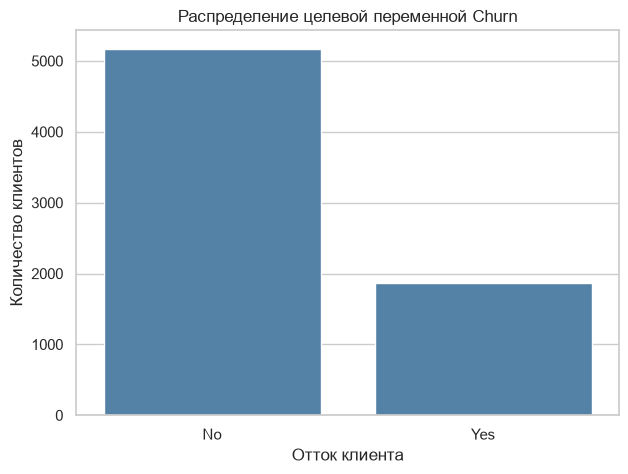

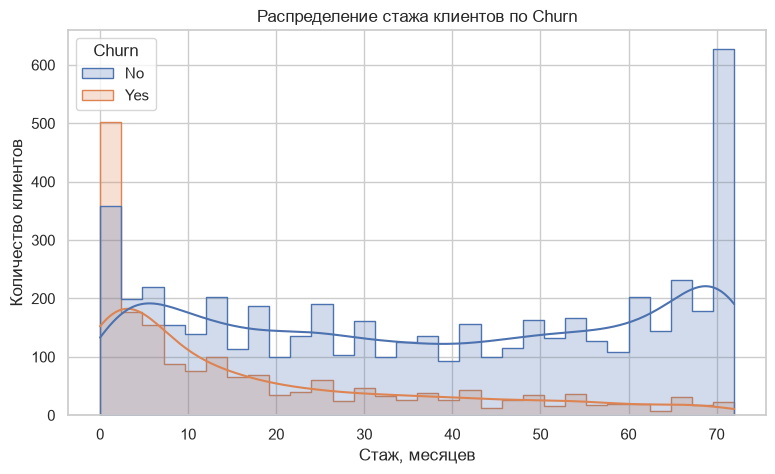

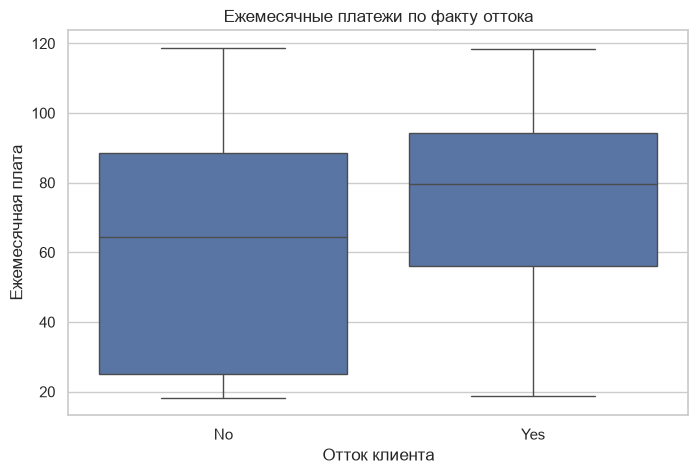

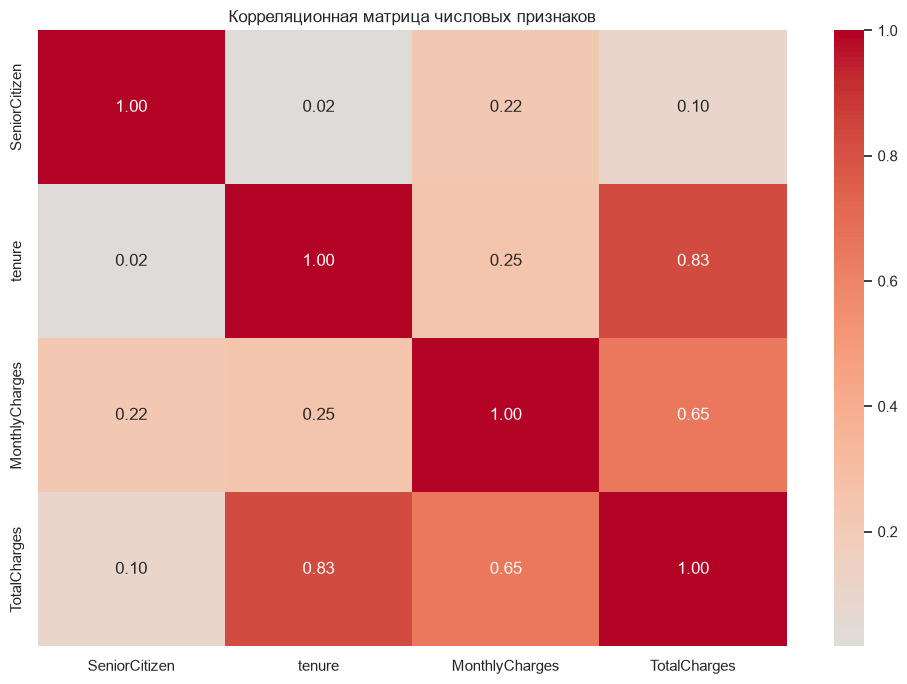

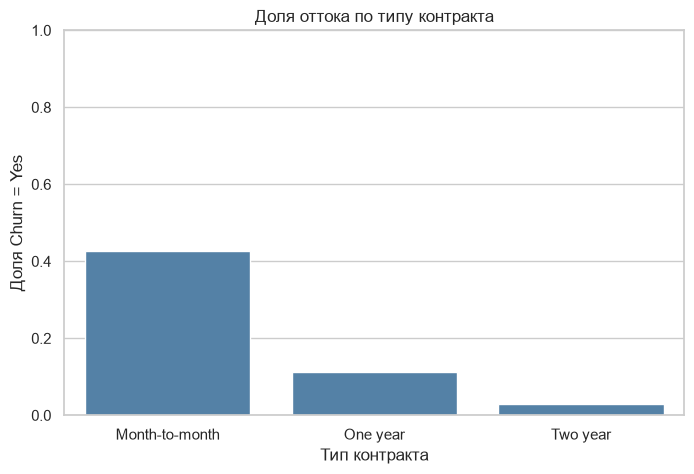

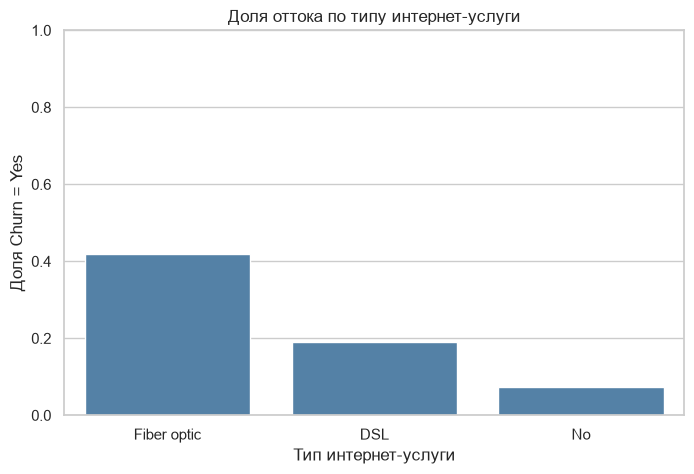

Пропусков в подготовленных данных: 0


,TenureYears,AvgMonthlyCharge,IsNewClient,HasMultipleServices,Churn
0,0.083333,14.925000,1,1,0
1,2.833333,53.985714,0,3,0
2,0.166667,36.050000,1,3,1
3,3.750000,40.016304,0,3,0
4,0.166667,50.550000,1,1,1


In [3]:
# Создаём копию исходных данных, чтобы сохранить оригинал без изменений
df = df_raw.copy()

# Пустые строки TotalCharges превращаем в NaN, затем заполняем медианой
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing_before = df.isna().sum().sort_values(ascending=False)
print("Пропуски до обработки:")
display(missing_before[missing_before > 0].to_frame("Количество"))

# Заполняем пропуски медианой числового столбца
total_charges_median = df["TotalCharges"].median()
df["TotalCharges"] = df["TotalCharges"].fillna(total_charges_median)
print("Медиана TotalCharges для заполнения:", round(total_charges_median, 2))
print("Пропусков после обработки:", int(df.isna().sum().sum()))

# График 1: количество клиентов в каждом классе целевой переменной
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], color="steelblue")
plt.title("Распределение целевой переменной Churn")
plt.xlabel("Отток клиента")
plt.ylabel("Количество клиентов")
plt.show()

# График 2: распределение стажа клиентов с разделением по оттоку
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, element="step")
plt.title("Распределение стажа клиентов по Churn")
plt.xlabel("Стаж, месяцев")
plt.ylabel("Количество клиентов")
plt.show()

# График 3: сравнение ежемесячных платежей ушедших и оставшихся клиентов
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", order=["No", "Yes"])
plt.title("Ежемесячные платежи по факту оттока")
plt.xlabel("Отток клиента")
plt.ylabel("Ежемесячная плата")
plt.show()

# График 4: корреляционная матрица числовых признаков
numeric_for_corr = df.select_dtypes(include=np.number)
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

# График 5: доля ушедших клиентов для разных типов контракта
contract_churn = df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int)).groupby("Contract")["ChurnFlag"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=contract_churn.index, y=contract_churn.values, color="steelblue")
plt.title("Доля оттока по типу контракта")
plt.xlabel("Тип контракта")
plt.ylabel("Доля Churn = Yes")
plt.ylim(0, 1)
plt.show()

# График 6: доля ушедших клиентов по типу интернет-подключения
internet_churn = df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int)).groupby("InternetService")["ChurnFlag"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=internet_churn.index, y=internet_churn.values, color="steelblue")
plt.title("Доля оттока по типу интернет-услуги")
plt.xlabel("Тип интернет-услуги")
plt.ylabel("Доля Churn = Yes")
plt.ylim(0, 1)
plt.show()

# Создаём признаки, описывающие стаж, средние начисления и нового клиента
df["TenureYears"] = df["tenure"] / 12
df["AvgMonthlyCharge"] = df["TotalCharges"] / (df["tenure"] + 1)
df["IsNewClient"] = (df["tenure"] <= 6).astype(int)

# Считаем количество подключённых дополнительных услуг со значением Yes
service_cols = [
    "PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"
]
df["HasMultipleServices"] = sum((df[col] == "Yes").astype(int) for col in service_cols)

# Кодируем целевую переменную и категориальные признаки
df["Churn"] = (df["Churn"] == "Yes").astype(int)
label_encoders = {}
for col in df.select_dtypes(include="object").columns:
    if col != "customerID":
        encoder = LabelEncoder()
        df[col] = encoder.fit_transform(df[col].astype(str))
        label_encoders[col] = encoder

# Проверяем итоговые пропуски и новые признаки
print("Пропусков в подготовленных данных:", int(df.isna().sum().sum()))
display(df[["TenureYears", "AvgMonthlyCharge", "IsNewClient", "HasMultipleServices", "Churn"]].head())

### Вывод по EDA и подготовке данных

На графиках видно, как классы распределены по количеству, как различается стаж и ежемесячная плата, а также как тип контракта и интернет-услуги связаны с долей оттока. 

Эти графики описывают ассоциации, а не доказывают причинность. 

Пустые значения `TotalCharges` преобразованы в пропуски и заполнены медианой. Добавлены `TenureYears`, `AvgMonthlyCharge`, `IsNewClient` и `HasMultipleServices`. Категориальные поля закодированы LabelEncoder, а `customerID` исключается из матрицы признаков.

## 6. Построение и обучение моделей

Для честного сравнения все четыре алгоритма обучаются на одном и том же train/test-разбиении. 

Используется `stratify=y`, чтобы сохранить близкую долю классов в обучающей и тестовой выборках. 

Доля тестовой выборки - 20%, `random_state=42` обеспечивает воспроизводимость. Для компенсации дисбаланса классов применяются веса классов или параметр `scale_pos_weight`. Время обучения каждой модели измеряется отдельно.

In [4]:
# Исключаем идентификатор и целевую переменную из признаков
feature_cols = [col for col in df.columns if col not in ["customerID", "Churn"]]
X = df[feature_cols].copy()
y = df["Churn"].copy()

# Делим данные со стратификацией, сохраняя долю ушедших клиентов
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Размер X_train:", X_train.shape, "| Размер X_test:", X_test.shape)
print("Доля Churn=1 в train:", round(y_train.mean(), 4))
print("Доля Churn=1 в test:", round(y_test.mean(), 4))

# Подготавливаем модели с параметрами, согласованными с заданием
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=10, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9, scale_pos_weight=2.77,
        random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,
        class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1
    ),
    "CatBoost": CatBoostClassifier(
        iterations=200, depth=6, learning_rate=0.1,
        auto_class_weights="Balanced", random_seed=RANDOM_STATE, verbose=0,
        allow_writing_files=False
    )
}

# Обучаем каждую модель и сохраняем фактическое время обучения
training_times = {}
for name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    training_times[name] = time.time() - start_time
    print(f"{name}: время обучения {training_times[name]:.3f} сек.")

# Создаём таблицу параметров и времени для отчёта
model_summary = pd.DataFrame({
    "Модель": list(models.keys()),
    "Тип": ["Bagging", "Boosting", "Boosting", "Boosting"],
    "Основные параметры": [
        "n_estimators=200, max_depth=10",
        "n_estimators=200, max_depth=6",
        "n_estimators=200, num_leaves=31",
        "iterations=200, depth=6"
    ],
    "Время обучения, сек": [training_times[name] for name in models]
})
display(model_summary)

Размер X_train: (5634, 23) | Размер X_test: (1409, 23)
Доля Churn=1 в train: 0.2654
Доля Churn=1 в test: 0.2654
Random Forest: время обучения 0.648 сек.
XGBoost: время обучения 1.187 сек.
LightGBM: время обучения 0.420 сек.
CatBoost: время обучения 0.889 сек.


,Модель,Тип,Основные параметры,"Время обучения, сек"
0,Random Forest,Bagging,"n_estimators=200, max_depth=10",0.648311
1,XGBoost,Boosting,"n_estimators=200, max_depth=6",1.186748
2,LightGBM,Boosting,"n_estimators=200, num_leaves=31",0.419578
3,CatBoost,Boosting,"iterations=200, depth=6",0.888595


### Вывод по обучению моделей

Все четыре модели обучены на одинаковых обучающих данных. 

Время обучения зависит от реализации алгоритма, параметров и среды выполнения, поэтому в таблице используется фактически измеренное значение, а не заранее заданная оценка. 

На следующем этапе сравним модели по единым метрикам на отложенной тестовой выборке.

## 7. Оценка качества

Для каждой модели рассчитываются Accuracy, Precision, Recall, F1 и ROC-AUC. 

**Accuracy** отражает общую долю верных ответов; **Precision** показывает, какая доля клиентов, предсказанных как уходящие, действительно ушла; **Recall** - какую долю всех ушедших удалось обнаружить; **F1** - гармоническое среднее Precision и Recall. **ROC-AUC** оценивает способность ранжировать ушедших выше оставшихся при разных порогах. 

Лучшую базовую модель выбираем по ROC-AUC, дополнительно учитывая Recall и F1.

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.7622,0.5373,0.7513,0.6265,0.8383
1,CatBoost,0.7559,0.5279,0.7594,0.6228,0.8381
2,LightGBM,0.7601,0.5344,0.7487,0.6236,0.8379
3,XGBoost,0.7715,0.5553,0.6979,0.6185,0.8294


Лучшая базовая модель по ROC-AUC: Random Forest

Classification report:
              precision    recall  f1-score   support

 Остался (0)       0.90      0.77      0.83      1035
    Ушёл (1)       0.54      0.75      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



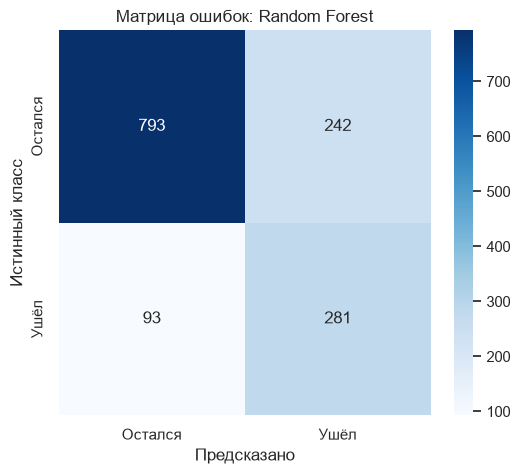

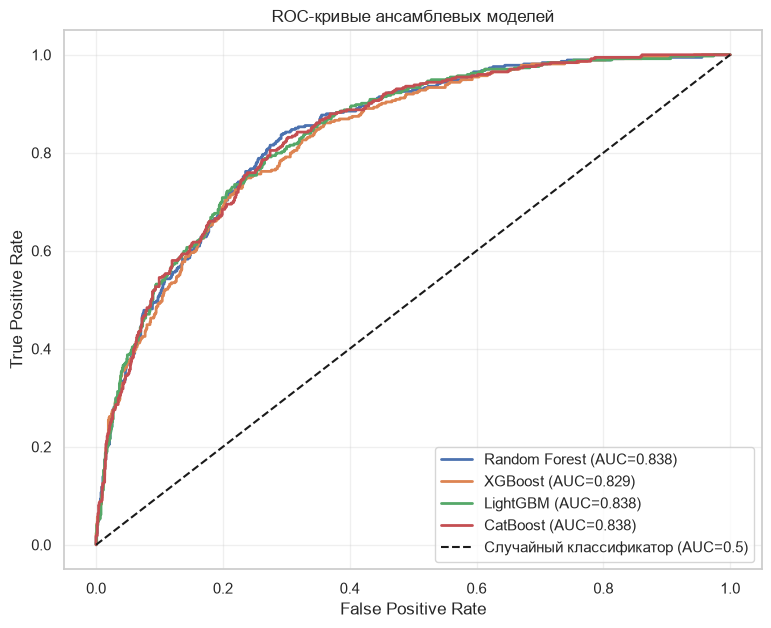

In [5]:
# Рассчитываем единый набор метрик для каждой модели на тестовых данных
def evaluate_model(model, X_eval, y_eval, name):
    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:, 1]
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred, zero_division=0),
        "Recall": recall_score(y_eval, y_pred, zero_division=0),
        "F1": f1_score(y_eval, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, y_prob)
    }

# Формируем сводную таблицу результатов
results = [evaluate_model(model, X_test, y_test, name) for name, model in models.items()]
results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(results_df.round(4))

# Выбираем лучшую базовую модель по ROC-AUC и получаем её прогнозы
best_baseline_name = results_df.loc[0, "Модель"]
best_baseline = models[best_baseline_name]
y_pred_best = best_baseline.predict(X_test)
y_prob_best = best_baseline.predict_proba(X_test)[:, 1]
print("Лучшая базовая модель по ROC-AUC:", best_baseline_name)
print("\nClassification report:")
print(classification_report(y_test, y_pred_best, target_names=["Остался (0)", "Ушёл (1)"], zero_division=0))

# Строим матрицу ошибок лучшей базовой модели
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Остался", "Ушёл"], yticklabels=["Остался", "Ушёл"])
plt.title(f"Матрица ошибок: {best_baseline_name}")
plt.xlabel("Предсказано")
plt.ylabel("Истинный класс")
plt.show()

# Строим ROC-кривые для четырёх моделей на одном графике
plt.figure(figsize=(9, 7))
for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], "k--", label="Случайный классификатор (AUC=0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые ансамблевых моделей")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Анализ качества

Таблица метрик выше содержит реальные результаты моделей на отложенной тестовой выборке. 

Лучшая базовая модель определяется по максимальному ROC-AUC. 

Матрица ошибок показывает число верно и неверно классифицированных клиентов каждого класса: особенно важно учитывать ложноотрицательные ответы, когда клиент с реальным оттоком классифицирован как оставшийся. 

ROC-кривая сравнивает компромисс между True Positive Rate и False Positive Rate при изменении порога.

## 8. Интерпретация и бизнес-инсайты

Важность признаков показывает, какие поля модель чаще всего использует для принятия решений, но не показывает направление влияния и не доказывает причинность.

 Для сопоставимости ниже рассматривается важность LightGBM и Random Forest. После этого результаты переводятся в бизнес-гипотезы, которые можно проверить экспериментом.

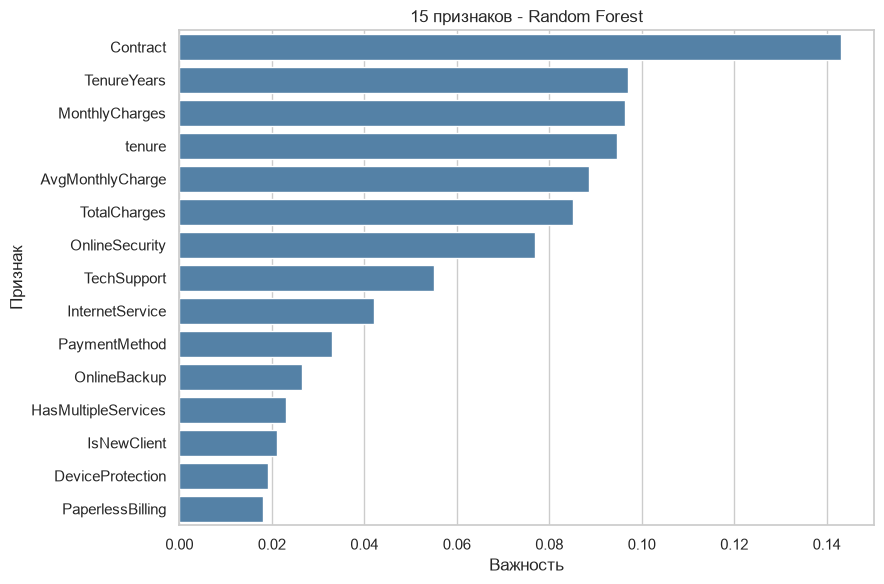

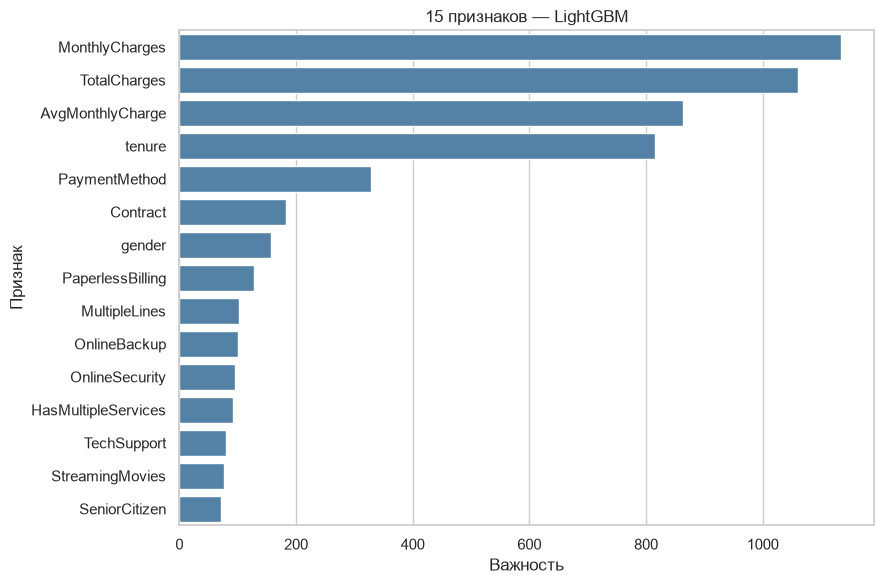

10 Random Forest:


,Признак,Важность
14,Contract,0.143075
19,TenureYears,0.097118
17,MonthlyCharges,0.096353
4,tenure,0.094697
20,AvgMonthlyCharge,0.088616
18,TotalCharges,0.085071
8,OnlineSecurity,0.076954
11,TechSupport,0.055146
7,InternetService,0.042136
16,PaymentMethod,0.033077


10 LightGBM:


,Признак,Важность
17,MonthlyCharges,1134
18,TotalCharges,1061
20,AvgMonthlyCharge,864
4,tenure,815
16,PaymentMethod,329
14,Contract,183
0,gender,157
15,PaperlessBilling,128
6,MultipleLines,103
9,OnlineBackup,100


Доля оттока по контракту:


,"Отток, %"
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


Доля оттока по интернет-услуге:


,"Отток, %"
InternetService,
DSL,18.96
Fiber optic,41.89
No,7.40


In [6]:
# Получаем важности признаков из Random Forest и LightGBM
importance_rf = pd.DataFrame({
    "Признак": feature_cols,
    "Важность": models["Random Forest"].feature_importances_
}).sort_values("Важность", ascending=False)
importance_lgbm = pd.DataFrame({
    "Признак": feature_cols,
    "Важность": models["LightGBM"].feature_importances_
}).sort_values("Важность", ascending=False)

# Показываем наиболее важные признаки Random Forest
plt.figure(figsize=(9, 6))
sns.barplot(data=importance_rf.head(15), x="Важность", y="Признак", color="steelblue")
plt.title("15 признаков - Random Forest")
plt.tight_layout()
plt.show()

# Показываем наиболее важные признаки LightGBM
plt.figure(figsize=(9, 6))
sns.barplot(data=importance_lgbm.head(15), x="Важность", y="Признак", color="steelblue")
plt.title("15 признаков — LightGBM")
plt.tight_layout()
plt.show()

# Выводим таблицы важностей для точного сравнения
print("10 Random Forest:")
display(importance_rf.head(10))
print("10 LightGBM:")
display(importance_lgbm.head(10))

# Вычисляем фактическую долю оттока по основным бизнес-сегментам
business_churn = df_raw.assign(ChurnFlag=(df_raw["Churn"] == "Yes").astype(int))
print("Доля оттока по контракту:")
display((business_churn.groupby("Contract")["ChurnFlag"].mean() * 100).round(2).rename("Отток, %").to_frame())
print("Доля оттока по интернет-услуге:")
display((business_churn.groupby("InternetService")["ChurnFlag"].mean() * 100).round(2).rename("Отток, %").to_frame())

### Бизнес-интерпретация

1. Если `Contract` входит в число наиболее важных признаков и доля оттока выше у клиентов с помесячным контрактом, стоит проверить предложение перехода на годовой контракт с прозрачной скидкой.

2. Если `tenure` или `IsNewClient` важны, целесообразно усилить сопровождение в первые месяцы: приветственные контакты, проверка качества подключения и помощь с настройкой услуг.

3. Если значимы `MonthlyCharges` и `TotalCharges`, следует проверить чувствительность клиентов к цене и предложить релевантные тарифы, не снижая цену всем клиентам без необходимости.

4. Если важны `OnlineSecurity` или `TechSupport`, можно протестировать пакетное предложение поддержки и безопасности для подходящих сегментов.

5. Рекомендации следует оценивать через A/B-тест: модель выявляет статистические связи, но сама по себе не доказывает, что изменение тарифа или услуги уменьшит отток.

## 9. Тюнинг гиперпараметров (Optuna)

Выполняется байесовская оптимизация параметров LightGBM. 

Целевая метрика - средний ROC-AUC на трёх фолдах стратифицированной кросс-валидации. 

Используются 20 испытаний, что соответствует минимальному объёму поиска из методических рекомендаций; для более тщательной настройки число испытаний можно увеличить до 30–50. 

Тестовая выборка не участвует в подборе параметров и используется только для финального сравнения.

In [7]:
# Импортируем Optuna и создаём функцию оценки набора гиперпараметров
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
        "num_leaves": trial.suggest_int("num_leaves", 10, 100, step=5),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "class_weight": "balanced",
        "random_state": RANDOM_STATE,
        "verbosity": -1
    }
    candidate = LGBMClassifier(**params)
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(candidate, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    return scores.mean()

# Запускаем поиск с фиксированным seed для воспроизводимости
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=20, show_progress_bar=False)

print(f"Лучший средний ROC-AUC на CV: {study.best_value:.4f}")
print("Лучшие параметры:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# Обучаем финальную модель на всём train и оцениваем на test
best_lgbm = LGBMClassifier(
    **study.best_params, class_weight="balanced",
    random_state=RANDOM_STATE, verbosity=-1
)
start_time = time.time()
best_lgbm.fit(X_train, y_train)
best_lgbm_time = time.time() - start_time
best_lgbm_prob = best_lgbm.predict_proba(X_test)[:, 1]
best_lgbm_pred = best_lgbm.predict(X_test)
baseline_lgbm_auc = roc_auc_score(y_test, models["LightGBM"].predict_proba(X_test)[:, 1])
tuned_lgbm_auc = roc_auc_score(y_test, best_lgbm_prob)
print(f"LightGBM baseline ROC-AUC на test: {baseline_lgbm_auc:.4f}")
print(f"LightGBM Optuna ROC-AUC на test:   {tuned_lgbm_auc:.4f}")
print(f"Изменение ROC-AUC: {tuned_lgbm_auc - baseline_lgbm_auc:+.4f}")
print(f"Время обучения оптимизированной модели: {best_lgbm_time:.3f} сек.")

# Сводим базовую и оптимизированную LightGBM в отдельную таблицу
tuned_comparison = pd.DataFrame([
    evaluate_model(models["LightGBM"], X_test, y_test, "LightGBM baseline"),
    evaluate_model(best_lgbm, X_test, y_test, "LightGBM (Optuna)")
])
display(tuned_comparison.round(4))

Лучший средний ROC-AUC на CV: 0.8493
Лучшие параметры:
  n_estimators: 350
  num_leaves: 95
  max_depth: 3
  learning_rate: 0.01947558230629543
  subsample: 0.522613644455269
  colsample_bytree: 0.6626651653816322
  min_child_samples: 22
  reg_alpha: 0.01217295809836997
  reg_lambda: 2.0651425578959257
LightGBM baseline ROC-AUC на test: 0.8379
LightGBM Optuna ROC-AUC на test:   0.8465
Изменение ROC-AUC: +0.0086
Время обучения оптимизированной модели: 0.155 сек.


,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,LightGBM baseline,0.7601,0.5344,0.7487,0.6236,0.8379
1,LightGBM (Optuna),0.7445,0.5119,0.8021,0.6250,0.8465


### Вывод по Optuna

Результат `study.best_value` - лучший средний ROC-AUC на кросс-валидации, а ROC-AUC на тесте - отдельная итоговая оценка. 

Прирост не гарантирован: оптимизация может как улучшить, так и не улучшить качество на тестовой выборке.

## 10. Интерпретация через SHAP

SHAP применяется к оптимизированной LightGBM. 

Summary plot даёт глобальное представление о влиянии признаков, waterfall plot объясняет прогноз конкретного клиента с максимальной предсказанной вероятностью оттока, а dependence plot показывает зависимость вклада одного из наиболее важных признаков от его значения. 

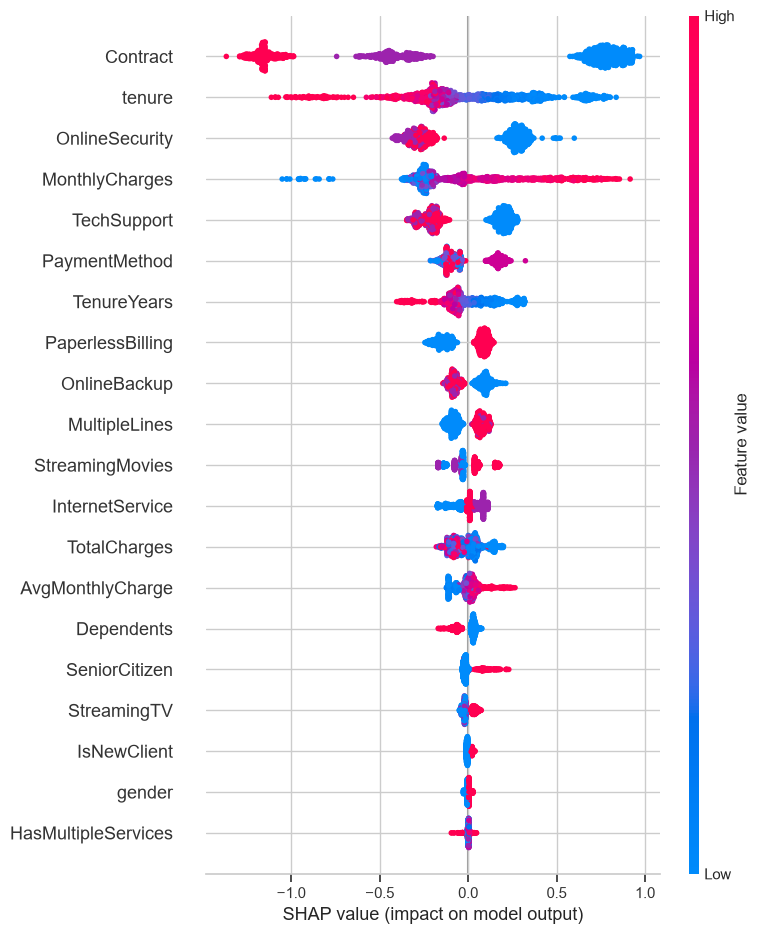

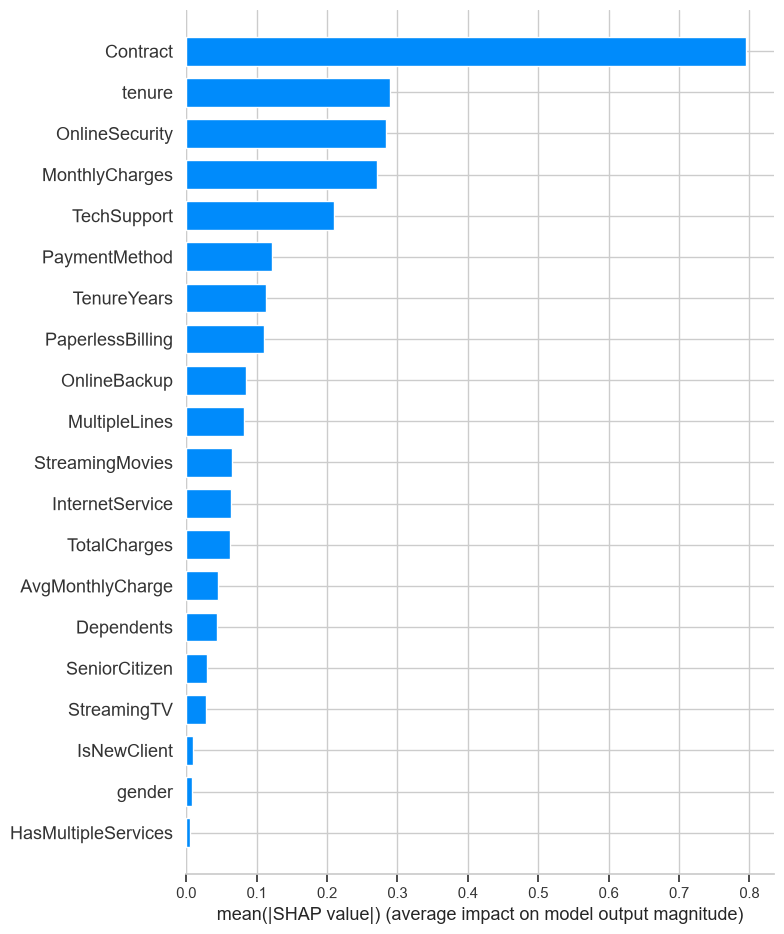

Индекс клиента в X_test: 1090
Предсказанная вероятность оттока: 0.9533


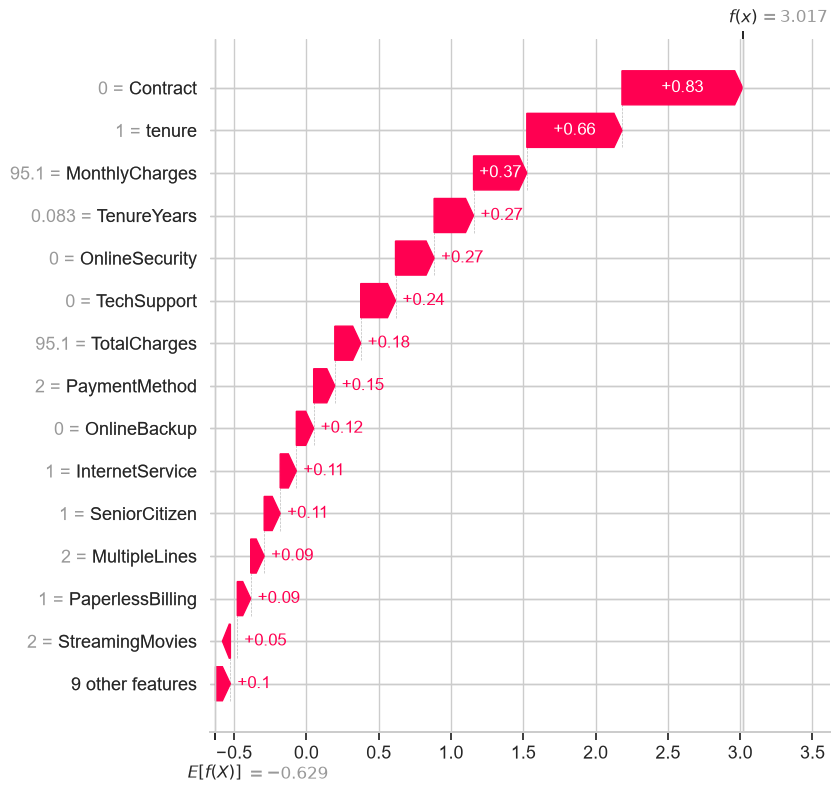

Признак для dependence plot: Contract


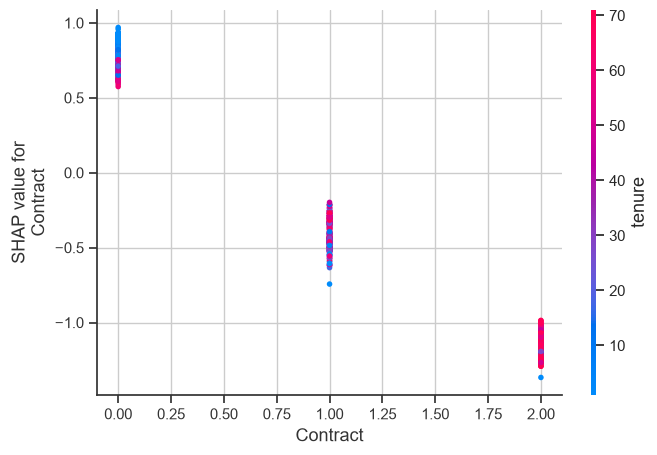

In [8]:
# Импортируем SHAP и создаём объяснитель для обученной модели LightGBM
import shap
explainer = shap.TreeExplainer(best_lgbm)

# Для бинарной LightGBM актуальные версии SHAP обычно возвращают матрицу (объекты, признаки)
shap_values = explainer.shap_values(X_test)
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = np.asarray(shap_values)
    if shap_values_class1.ndim == 3:
        shap_values_class1 = shap_values_class1[:, :, 1]

# Строим summary plot для глобального анализа признаков
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=True)

# Строим bar plot по среднему абсолютному SHAP-вкладу
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=True)

# Находим тестового клиента с наибольшей вероятностью оттока
worst_idx = int(np.argmax(best_lgbm_prob))
print(f"Индекс клиента в X_test: {worst_idx}")
print(f"Предсказанная вероятность оттока: {best_lgbm_prob[worst_idx]:.4f}")

# Определяем базовое значение для waterfall-графика с учётом формата SHAP
expected_value = explainer.expected_value
if isinstance(expected_value, (list, np.ndarray)) and np.asarray(expected_value).size > 1:
    base_value = float(np.asarray(expected_value).reshape(-1)[-1])
else:
    base_value = float(np.asarray(expected_value).reshape(-1)[0])

# Формируем объяснение одного клиента и строим waterfall plot
shap_exp = shap.Explanation(
    values=shap_values_class1[worst_idx],
    base_values=base_value,
    data=X_test.iloc[worst_idx].values,
    feature_names=X_test.columns.tolist()
)
shap.plots.waterfall(shap_exp, max_display=15)

# Строим dependence plot для признака с наибольшей средней абсолютной важностью SHAP
mean_abs_shap = np.abs(shap_values_class1).mean(axis=0)
top_shap_feature = X_test.columns[int(np.argmax(mean_abs_shap))]
print("Признак для dependence plot:", top_shap_feature)
shap.dependence_plot(top_shap_feature, shap_values_class1, X_test)

### Вывод по SHAP

**Summary plot** показывает, какие признаки в среднем сильнее всего влияют на прогнозы модели, а цвет отражает низкие и высокие значения признаков. Waterfall plot показывает, какие характеристики конкретного клиента увеличивают или уменьшают выход модели относительно базового значения. Dependence plot помогает увидеть форму связи признака с SHAP-вкладом. 

## 11. Сохранение модели и метаданных

Сохраняются четыре базовые модели, оптимизированная модель, кодировщики, список признаков и JSON с метриками. 

Артефакты размещаются в каталоге `models/`. Для переносимости в репозиторий используется относительный путь. 

Версии библиотек следует фиксировать в `requirements.txt`, поскольку совместимость сериализованных моделей зависит от окружения.

In [ ]:
# Создаём каталоги для моделей и вспомогательных файлов
os.makedirs("models", exist_ok=True)

# Сохраняем все четыре базовые модели и лучшую оптимизированную модель
model_files = {
    "rf_model.pkl": models["Random Forest"],
    "xgb_model.pkl": models["XGBoost"],
    "lgbm_model.pkl": models["LightGBM"],
    "cat_model.pkl": models["CatBoost"],
    "best_model.pkl": best_lgbm
}
for filename, model in model_files.items():
    joblib.dump(model, os.path.join("models", filename))

# Сохраняем LabelEncoder для воспроизведения преобразования категорий
joblib.dump(label_encoders, "models/label_encoders.pkl")

# Сохраняем порядок признаков, требуемый моделью при прогнозировании
with open("models/feature_cols.json", "w", encoding="utf-8") as file:
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)

# Сохраняем результаты метрик и параметры Optuna в JSON
metrics_payload = {
    "baseline_models": results,
    "training_times_seconds": training_times,
    "best_baseline_model": best_baseline_name,
    "lightgbm_baseline_test_roc_auc": float(baseline_lgbm_auc),
    "lightgbm_optuna_cv_roc_auc": float(study.best_value),
    "lightgbm_optuna_test_roc_auc": float(tuned_lgbm_auc),
    "lightgbm_optuna_test_metrics": evaluate_model(best_lgbm, X_test, y_test, "LightGBM (Optuna)"),
    "best_params": study.best_params,
    "random_state": RANDOM_STATE
}
with open("models/metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics_payload, file, ensure_ascii=False, indent=2)

# Записываем описание датасета в каталог data для репозитория
os.makedirs("data", exist_ok=True)
df_raw.to_csv("data/telco_churn.csv", index=False)
with open("data/churn_info.md", "w", encoding="utf-8") as file:
    file.write(
        "# Telco Customer Churn\n\n"
        f"- Записей: {df_raw.shape[0]}\n"
        f"- Столбцов: {df_raw.shape[1]}\n"
        f"- Ушедшие клиенты: {(df_raw['Churn'] == 'Yes').sum()} "
        f"({(df_raw['Churn'] == 'Yes').mean()*100:.2f}%)\n"
        f"- Оставшиеся клиенты: {(df_raw['Churn'] == 'No').sum()} "
        f"({(df_raw['Churn'] == 'No').mean()*100:.2f}%)\n"
        "- Источник: https://www.kaggle.com/datasets/blastchar/telco-customer-churn\n"
    )

print("Сохранены файлы:")
for path in sorted(os.listdir("models")):
    print(" -", os.path.join("models", path))

Сохранены файлы:
 - models\best_model.pkl
 - models\cat_model.pkl
 - models\feature_cols.json
 - models\label_encoders.pkl
 - models\lgbm_model.pkl
 - models\metrics.json
 - models\rf_model.pkl
 - models\xgb_model.pkl


### Вывод по сохранению

Файлы моделей и метаданные записаны в `models/`, а копия набора данных и его краткое описание - в `data/`. 

## 12. Загрузка модели из репозитория

Код ниже проверяет HTTP-статус, загружает модель и список признаков, а затем сравнивает прогнозы загруженной и исходной моделей на трёх клиентах.

In [1]:
import requests
from io import BytesIO
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "ZhdanovaAnna/ml-course-zhdanova/main/"
    "module-3-churn"
)
# Локальная проверка сохранённой модели работает до публикации GitHub-репозитория
loaded_local = joblib.load("models/best_model.pkl")
with open("models/feature_cols.json", "r", encoding="utf-8") as file:
    feature_cols_loaded = json.load(file)

# Проверяем совпадение прогнозов локально сохранённой и исходной моделей
y_pred_loaded_local = loaded_local.predict(X_test.iloc[:3][feature_cols_loaded])
y_pred_original = best_lgbm.predict(X_test.iloc[:3][feature_cols])
print("Локально загруженная модель:", y_pred_loaded_local)
print("Исходная модель:            ", y_pred_original)
print("Прогнозы совпадают:", bool(np.array_equal(y_pred_loaded_local, y_pred_original)))

model_response = requests.get(f"{BASE_URL}/models/best_model.pkl", timeout=30)
model_response.raise_for_status()
best_lgbm_from_github = joblib.load(BytesIO(model_response.content))
features_response = requests.get(f"{BASE_URL}/models/feature_cols.json", timeout=30)
features_response.raise_for_status()
feature_cols_from_github = features_response.json()
predictions_github = best_lgbm_from_github.predict(X_test.iloc[:3][feature_cols_from_github])
print("Прогнозы из GitHub:", predictions_github)
print("Совпадают с исходными:", np.array_equal(predictions_github, y_pred_original))

Локально загруженная модель: [0 1 0]
Исходная модель:             [0 1 0]
Прогнозы совпадают: True
Прогнозы из GitHub: [0 1 0]
Совпадают с исходными: True


### Вывод по загрузке

Локальная проверка подтверждает, что сериализованная модель загружается и даёт те же предсказания, что и объект модели в памяти.

## 13. Выводы

### 13.1. Что получилось

1. Подготовлен датасет Telco Customer Churn, преобразован `TotalCharges`, закодированы категориальные признаки и добавлены производные признаки.

2. Обучены и сопоставлены Random Forest, XGBoost, LightGBM и CatBoost.

3. Рассчитаны Accuracy, Precision, Recall, F1 и ROC-AUC; построены матрица ошибок и ROC-кривые.

4. Выполнен подбор гиперпараметров LightGBM с Optuna и интерпретация модели через SHAP.

5. Сохранены модели и метаданные для последующего использования.

**Фактические значения метрик** находятся в таблицах разделов 7 и 9. 

### 13.2. Трудности

1. **Дисбаланс классов:** ушедших клиентов меньше, поэтому Accuracy не отражает качество обнаружения оттока полностью.

2. **Пропуски `TotalCharges`:** пустые строки необходимо преобразовать в числовые пропуски и заполнить выбранной статистикой.

3. **Категориальные признаки:** кодирование превращает категории в числа; для некоторых алгоритмов такое представление может задавать искусственный порядок.

4. **Вычислительные затраты:** кросс-валидация Optuna и SHAP требуют дополнительного времени по сравнению с базовым обучением.

5. **Переносимость модели:** для загрузки из GitHub нужны реальные ссылки и совместимые версии библиотек.

### 13.3. Возможные улучшения

1. Подобрать порог классификации под стоимость пропущенного оттока и стоимость контакта с клиентом.

2. Проверить `StackingClassifier`, объединяющий вероятности четырёх моделей.

3. Сравнить балансировку классов с SMOTE, выполняя её только внутри обучающих фолдов.

4. Использовать One-Hot Encoding или нативную обработку категорий CatBoost и сравнить результаты.

5. Увеличить число испытаний Optuna и использовать более строгую кросс-валидацию.

6. Оценить калибровку вероятностей с помощью calibration curve и Brier score.

7. Проверить стабильность качества на временном разделении данных, если доступны даты наблюдений.

8. Добавить мониторинг дрейфа данных и версионирование модели и признаков.

9. Провести A/B-тест удерживающих предложений для оценки реального бизнес-эффекта.

## 14. Источники

1. Breiman, L. (2001). *Random Forests*. Machine Learning, 45, 5–32. https://doi.org/10.1023/A:1010933404324

2. Chen, T., & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. Proceedings of KDD 2016. https://doi.org/10.1145/2939672.2939785

3. Ke, G. et al. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. NeurIPS 2017.

4. Prokhorenkova, L. et al. (2018). *CatBoost: unbiased boosting with categorical features*. NeurIPS 2018.

6. Akiba, T. et al. (2019). *Optuna: A Next-generation Hyperparameter Optimization Framework*. KDD 2019.

7. Kaggle. *Telco Customer Churn Dataset*. https://www.kaggle.com/datasets/blastchar/telco-customer-churn

8. Scikit-learn documentation. *Model evaluation: quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html

## Приложение. Полный код и зависимости

Все этапы реализации приведены в кодовых ячейках соответствующих разделов выше. Для воспроизведения рекомендуется установить библиотеки:

```text
numpy==1.26.4
pandas==2.2.3
matplotlib==3.9.2
seaborn==0.13.2
scikit-learn==1.5.2
xgboost==2.1.2
lightgbm==4.5.0
catboost==1.2.7
optuna==4.1.0
shap==0.46.0
joblib==1.4.2
jupyter==1.1.1
ipykernel==6.29.5
```

```python
# %%
# Импортируем библиотеки
import os
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Настраиваем отображение графиков и подавляем только предупреждения
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

df_raw = pd.read_csv('data/telco_churn.csv')

# Выводим обязательные сведения о размере и первых наблюдениях
print("Размер датасета:", df_raw.shape)
display(df_raw.head())
print("\nТипы данных и непустые значения:")
df_raw.info()
print("\nОписательная статистика:")
display(df_raw.describe(include="all").T)

# Показываем распределение целевой переменной в количестве и процентах
display(df_raw["Churn"].value_counts().rename("Количество").to_frame())
display((df_raw["Churn"].value_counts(normalize=True) * 100).round(2).rename("Доля, %").to_frame())

# %%
# Создаём копию исходных данных, чтобы сохранить оригинал без изменений
df = df_raw.copy()

# Пустые строки TotalCharges превращаем в NaN, затем заполняем медианой
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing_before = df.isna().sum().sort_values(ascending=False)
print("Пропуски до обработки:")
display(missing_before[missing_before > 0].to_frame("Количество"))

# Заполняем пропуски медианой числового столбца
total_charges_median = df["TotalCharges"].median()
df["TotalCharges"] = df["TotalCharges"].fillna(total_charges_median)
print("Медиана TotalCharges для заполнения:", round(total_charges_median, 2))
print("Пропусков после обработки:", int(df.isna().sum().sum()))

# График 1: количество клиентов в каждом классе целевой переменной
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], color="steelblue")
plt.title("Распределение целевой переменной Churn")
plt.xlabel("Отток клиента")
plt.ylabel("Количество клиентов")
plt.show()

# График 2: распределение стажа клиентов с разделением по оттоку
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, element="step")
plt.title("Распределение стажа клиентов по Churn")
plt.xlabel("Стаж, месяцев")
plt.ylabel("Количество клиентов")
plt.show()

# График 3: сравнение ежемесячных платежей ушедших и оставшихся клиентов
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", order=["No", "Yes"])
plt.title("Ежемесячные платежи по факту оттока")
plt.xlabel("Отток клиента")
plt.ylabel("Ежемесячная плата")
plt.show()

# График 4: корреляционная матрица числовых признаков
numeric_for_corr = df.select_dtypes(include=np.number)
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

# График 5: доля ушедших клиентов для разных типов контракта
contract_churn = df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int)).groupby("Contract")["ChurnFlag"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=contract_churn.index, y=contract_churn.values, color="steelblue")
plt.title("Доля оттока по типу контракта")
plt.xlabel("Тип контракта")
plt.ylabel("Доля Churn = Yes")
plt.ylim(0, 1)
plt.show()

# График 6: доля ушедших клиентов по типу интернет-подключения
internet_churn = df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int)).groupby("InternetService")["ChurnFlag"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=internet_churn.index, y=internet_churn.values, color="steelblue")
plt.title("Доля оттока по типу интернет-услуги")
plt.xlabel("Тип интернет-услуги")
plt.ylabel("Доля Churn = Yes")
plt.ylim(0, 1)
plt.show()

# Создаём признаки, описывающие стаж, средние начисления и нового клиента
df["TenureYears"] = df["tenure"] / 12
df["AvgMonthlyCharge"] = df["TotalCharges"] / (df["tenure"] + 1)
df["IsNewClient"] = (df["tenure"] <= 6).astype(int)

# Считаем количество подключённых дополнительных услуг со значением Yes
service_cols = [
    "PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"
]
df["HasMultipleServices"] = sum((df[col] == "Yes").astype(int) for col in service_cols)

# Кодируем целевую переменную и категориальные признаки
df["Churn"] = (df["Churn"] == "Yes").astype(int)
label_encoders = {}
for col in df.select_dtypes(include="object").columns:
    if col != "customerID":
        encoder = LabelEncoder()
        df[col] = encoder.fit_transform(df[col].astype(str))
        label_encoders[col] = encoder

# Проверяем итоговые пропуски и новые признаки
print("Пропусков в подготовленных данных:", int(df.isna().sum().sum()))
display(df[["TenureYears", "AvgMonthlyCharge", "IsNewClient", "HasMultipleServices", "Churn"]].head())

# %%
# Исключаем идентификатор и целевую переменную из признаков
feature_cols = [col for col in df.columns if col not in ["customerID", "Churn"]]
X = df[feature_cols].copy()
y = df["Churn"].copy()

# Делим данные со стратификацией, сохраняя долю ушедших клиентов
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Размер X_train:", X_train.shape, "| Размер X_test:", X_test.shape)
print("Доля Churn=1 в train:", round(y_train.mean(), 4))
print("Доля Churn=1 в test:", round(y_test.mean(), 4))

# Подготавливаем модели с параметрами, согласованными с заданием
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=10, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9, scale_pos_weight=2.77,
        random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,
        class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1
    ),
    "CatBoost": CatBoostClassifier(
        iterations=200, depth=6, learning_rate=0.1,
        auto_class_weights="Balanced", random_seed=RANDOM_STATE, verbose=0,
        allow_writing_files=False
    )
}

# Обучаем каждую модель и сохраняем фактическое время обучения
training_times = {}
for name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    training_times[name] = time.time() - start_time
    print(f"{name}: время обучения {training_times[name]:.3f} сек.")

# Создаём таблицу параметров и времени для отчёта
model_summary = pd.DataFrame({
    "Модель": list(models.keys()),
    "Тип": ["Bagging", "Boosting", "Boosting", "Boosting"],
    "Основные параметры": [
        "n_estimators=200, max_depth=10",
        "n_estimators=200, max_depth=6",
        "n_estimators=200, num_leaves=31",
        "iterations=200, depth=6"
    ],
    "Время обучения, сек": [training_times[name] for name in models]
})
display(model_summary)

# %%
# Рассчитываем единый набор метрик для каждой модели на тестовых данных
def evaluate_model(model, X_eval, y_eval, name):
    y_pred = model.predict(X_eval)
    y_prob = model.predict_proba(X_eval)[:, 1]
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_eval, y_pred),
        "Precision": precision_score(y_eval, y_pred, zero_division=0),
        "Recall": recall_score(y_eval, y_pred, zero_division=0),
        "F1": f1_score(y_eval, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, y_prob)
    }

# Формируем сводную таблицу результатов
results = [evaluate_model(model, X_test, y_test, name) for name, model in models.items()]
results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(results_df.round(4))

# Выбираем лучшую базовую модель по ROC-AUC и получаем её прогнозы
best_baseline_name = results_df.loc[0, "Модель"]
best_baseline = models[best_baseline_name]
y_pred_best = best_baseline.predict(X_test)
y_prob_best = best_baseline.predict_proba(X_test)[:, 1]
print("Лучшая базовая модель по ROC-AUC:", best_baseline_name)
print("\nClassification report:")
print(classification_report(y_test, y_pred_best, target_names=["Остался (0)", "Ушёл (1)"], zero_division=0))

# Строим матрицу ошибок лучшей базовой модели
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Остался", "Ушёл"], yticklabels=["Остался", "Ушёл"])
plt.title(f"Матрица ошибок: {best_baseline_name}")
plt.xlabel("Предсказано")
plt.ylabel("Истинный класс")
plt.show()

# Строим ROC-кривые для четырёх моделей на одном графике
plt.figure(figsize=(9, 7))
for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc_value = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], "k--", label="Случайный классификатор (AUC=0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые ансамблевых моделей")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

%%

# Получаем важности признаков из Random Forest и LightGBM
importance_rf = pd.DataFrame({
    "Признак": feature_cols,
    "Важность": models["Random Forest"].feature_importances_
}).sort_values("Важность", ascending=False)
importance_lgbm = pd.DataFrame({
    "Признак": feature_cols,
    "Важность": models["LightGBM"].feature_importances_
}).sort_values("Важность", ascending=False)

# Показываем наиболее важные признаки Random Forest
plt.figure(figsize=(9, 6))
sns.barplot(data=importance_rf.head(15), x="Важность", y="Признак", color="steelblue")
plt.title("15 признаков - Random Forest")
plt.tight_layout()
plt.show()

# Показываем наиболее важные признаки LightGBM
plt.figure(figsize=(9, 6))
sns.barplot(data=importance_lgbm.head(15), x="Важность", y="Признак", color="steelblue")
plt.title("15 признаков — LightGBM")
plt.tight_layout()
plt.show()

# Выводим таблицы важностей для точного сравнения
print("10 Random Forest:")
display(importance_rf.head(10))
print("10 LightGBM:")
display(importance_lgbm.head(10))

# Вычисляем фактическую долю оттока по основным бизнес-сегментам
business_churn = df_raw.assign(ChurnFlag=(df_raw["Churn"] == "Yes").astype(int))
print("Доля оттока по контракту:")
display((business_churn.groupby("Contract")["ChurnFlag"].mean() * 100).round(2).rename("Отток, %").to_frame())
print("Доля оттока по интернет-услуге:")
display((business_churn.groupby("InternetService")["ChurnFlag"].mean() * 100).round(2).rename("Отток, %").to_frame())

# %%
# Импортируем Optuna и создаём функцию оценки набора гиперпараметров
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
        "num_leaves": trial.suggest_int("num_leaves", 10, 100, step=5),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "class_weight": "balanced",
        "random_state": RANDOM_STATE,
        "verbosity": -1
    }
    candidate = LGBMClassifier(**params)
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(candidate, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    return scores.mean()

# Запускаем поиск с фиксированным seed для воспроизводимости
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=20, show_progress_bar=False)

print(f"Лучший средний ROC-AUC на CV: {study.best_value:.4f}")
print("Лучшие параметры:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

# Обучаем финальную модель на всём train и оцениваем на test
best_lgbm = LGBMClassifier(
    **study.best_params, class_weight="balanced",
    random_state=RANDOM_STATE, verbosity=-1
)
start_time = time.time()
best_lgbm.fit(X_train, y_train)
best_lgbm_time = time.time() - start_time
best_lgbm_prob = best_lgbm.predict_proba(X_test)[:, 1]
best_lgbm_pred = best_lgbm.predict(X_test)
baseline_lgbm_auc = roc_auc_score(y_test, models["LightGBM"].predict_proba(X_test)[:, 1])
tuned_lgbm_auc = roc_auc_score(y_test, best_lgbm_prob)
print(f"LightGBM baseline ROC-AUC на test: {baseline_lgbm_auc:.4f}")
print(f"LightGBM Optuna ROC-AUC на test:   {tuned_lgbm_auc:.4f}")
print(f"Изменение ROC-AUC: {tuned_lgbm_auc - baseline_lgbm_auc:+.4f}")
print(f"Время обучения оптимизированной модели: {best_lgbm_time:.3f} сек.")

# Сводим базовую и оптимизированную LightGBM в отдельную таблицу
tuned_comparison = pd.DataFrame([
    evaluate_model(models["LightGBM"], X_test, y_test, "LightGBM baseline"),
    evaluate_model(best_lgbm, X_test, y_test, "LightGBM (Optuna)")
])
display(tuned_comparison.round(4))

# %%
# Импортируем SHAP и создаём объяснитель для обученной модели LightGBM
import shap
explainer = shap.TreeExplainer(best_lgbm)

# Для бинарной LightGBM актуальные версии SHAP обычно возвращают матрицу (объекты, признаки)
shap_values = explainer.shap_values(X_test)
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = np.asarray(shap_values)
    if shap_values_class1.ndim == 3:
        shap_values_class1 = shap_values_class1[:, :, 1]

# Строим summary plot для глобального анализа признаков
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=True)

# Строим bar plot по среднему абсолютному SHAP-вкладу
shap.summary_plot(shap_values_class1, X_test, plot_type="bar", show=True)

# Находим тестового клиента с наибольшей вероятностью оттока
worst_idx = int(np.argmax(best_lgbm_prob))
print(f"Индекс клиента в X_test: {worst_idx}")
print(f"Предсказанная вероятность оттока: {best_lgbm_prob[worst_idx]:.4f}")

# Определяем базовое значение для waterfall-графика с учётом формата SHAP
expected_value = explainer.expected_value
if isinstance(expected_value, (list, np.ndarray)) and np.asarray(expected_value).size > 1:
    base_value = float(np.asarray(expected_value).reshape(-1)[-1])
else:
    base_value = float(np.asarray(expected_value).reshape(-1)[0])

# Формируем объяснение одного клиента и строим waterfall plot
shap_exp = shap.Explanation(
    values=shap_values_class1[worst_idx],
    base_values=base_value,
    data=X_test.iloc[worst_idx].values,
    feature_names=X_test.columns.tolist()
)
shap.plots.waterfall(shap_exp, max_display=15)

# Строим dependence plot для признака с наибольшей средней абсолютной важностью SHAP
mean_abs_shap = np.abs(shap_values_class1).mean(axis=0)
top_shap_feature = X_test.columns[int(np.argmax(mean_abs_shap))]
print("Признак для dependence plot:", top_shap_feature)
shap.dependence_plot(top_shap_feature, shap_values_class1, X_test)

# %%
# Создаём каталоги для моделей и вспомогательных файлов
os.makedirs("models", exist_ok=True)

# Сохраняем все четыре базовые модели и лучшую оптимизированную модель
model_files = {
    "rf_model.pkl": models["Random Forest"],
    "xgb_model.pkl": models["XGBoost"],
    "lgbm_model.pkl": models["LightGBM"],
    "cat_model.pkl": models["CatBoost"],
    "best_model.pkl": best_lgbm
}
for filename, model in model_files.items():
    joblib.dump(model, os.path.join("models", filename))

# Сохраняем LabelEncoder для воспроизведения преобразования категорий
joblib.dump(label_encoders, "models/label_encoders.pkl")

# Сохраняем порядок признаков, требуемый моделью при прогнозировании
with open("models/feature_cols.json", "w", encoding="utf-8") as file:
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)

# Сохраняем результаты метрик и параметры Optuna в JSON
metrics_payload = {
    "baseline_models": results,
    "training_times_seconds": training_times,
    "best_baseline_model": best_baseline_name,
    "lightgbm_baseline_test_roc_auc": float(baseline_lgbm_auc),
    "lightgbm_optuna_cv_roc_auc": float(study.best_value),
    "lightgbm_optuna_test_roc_auc": float(tuned_lgbm_auc),
    "lightgbm_optuna_test_metrics": evaluate_model(best_lgbm, X_test, y_test, "LightGBM (Optuna)"),
    "best_params": study.best_params,
    "random_state": RANDOM_STATE
}
with open("models/metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics_payload, file, ensure_ascii=False, indent=2)

# Записываем описание датасета в каталог data для репозитория
os.makedirs("data", exist_ok=True)
df_raw.to_csv("data/telco_churn.csv", index=False)
with open("data/churn_info.md", "w", encoding="utf-8") as file:
    file.write(
        "# Telco Customer Churn\n\n"
        f"- Записей: {df_raw.shape[0]}\n"
        f"- Столбцов: {df_raw.shape[1]}\n"
        f"- Ушедшие клиенты: {(df_raw['Churn'] == 'Yes').sum()} "
        f"({(df_raw['Churn'] == 'Yes').mean()*100:.2f}%)\n"
        f"- Оставшиеся клиенты: {(df_raw['Churn'] == 'No').sum()} "
        f"({(df_raw['Churn'] == 'No').mean()*100:.2f}%)\n"
        "- Источник: https://www.kaggle.com/datasets/blastchar/telco-customer-churn\n"
    )

print("Сохранены файлы:")
for path in sorted(os.listdir("models")):
    print(" -", os.path.join("models", path))

# %%
import requests
from io import BytesIO
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "ZhdanovaAnna/ml-course-zhdanova/main/"
    "module-3-churn"
)
# Локальная проверка сохранённой модели работает до публикации GitHub-репозитория
loaded_local = joblib.load("models/best_model.pkl")
with open("models/feature_cols.json", "r", encoding="utf-8") as file:
    feature_cols_loaded = json.load(file)

# Проверяем совпадение прогнозов локально сохранённой и исходной моделей
y_pred_loaded_local = loaded_local.predict(X_test.iloc[:3][feature_cols_loaded])
y_pred_original = best_lgbm.predict(X_test.iloc[:3][feature_cols])
print("Локально загруженная модель:", y_pred_loaded_local)
print("Исходная модель:            ", y_pred_original)
print("Прогнозы совпадают:", bool(np.array_equal(y_pred_loaded_local, y_pred_original)))

model_response = requests.get(f"{BASE_URL}/models/best_model.pkl", timeout=30)
model_response.raise_for_status()
best_lgbm_from_github = joblib.load(BytesIO(model_response.content))
features_response = requests.get(f"{BASE_URL}/models/feature_cols.json", timeout=30)
features_response.raise_for_status()
feature_cols_from_github = features_response.json()
predictions_github = best_lgbm_from_github.predict(X_test.iloc[:3][feature_cols_from_github])
print("Прогнозы из GitHub:", predictions_github)
print("Совпадают с исходными:", np.array_equal(predictions_github, y_pred_original))
```